# Project 3. Part 2 - graph visual

Last update: 05/23/2024

Title: Streamlining the Aggregation of Causal Loop Diagrams: A Thematic Labeling and Adjacency Matrix Approach

Overview: 
Making the aggregate Mental Map readable using gravis! 


In [59]:
# Gravis - Interactive UI network graph 
import pickle
import os 
import sys

import numpy as np
import gravis as gv
import networkx as nx
import matplotlib.pyplot as plt
# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

import parse_cld
import cld_nx
import data_io

In [78]:


# Create a directed graph
G1 = nx.DiGraph()

# Add nodes
nodes = ["A", "B", "C", "D"]
G1.add_nodes_from(nodes)

# Add directed edges with weights
edges = [("A", "B", 1), ("B", "C", 1), ("C", "D", 1), ("D", "A", 1), ("A", "C", 1)]
G1.add_weighted_edges_from(edges)
G1 = cld_nx.set_node_attributes(G1, '1')
G1 = cld_nx.set_edge_attributes(G1, '1')

# Draw the graph
pos = nx.circular_layout(G1)  # positions for all nodes

plt.figure(figsize=(8, 6))
nx.draw(G1, pos, with_labels=True, node_size=700, node_color='lightgreen', font_size=15, font_color='black', arrows=True)
labels = nx.get_edge_attributes(G1, 'weight')
nx.draw_networkx_edge_labels(G1, pos, edge_labels=labels)

plt.title("Directed G1 with Weights")
plt.show()


TypeError: set_node_attributes() missing 1 required positional argument: 'cld_name'

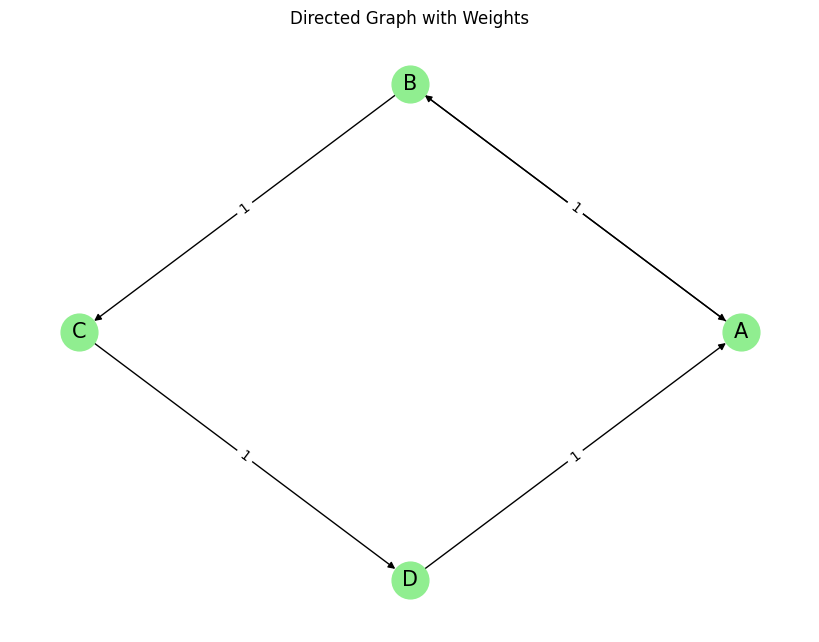

In [73]:
# Create a directed graph
G2 = nx.DiGraph()

# Add nodes
nodes = ["A", "B", "C", "D"]
G2.add_nodes_from(nodes)

# Add directed edges with weights
edges = [("B", "A", 1), ("B", "C", 1), ("C", "D", 1), ("D", "A", 1), ("A", "B", 1)]
G2.add_weighted_edges_from(edges)
G2 = cld_nx.set_node_attributes(G2, 'cld', '2')

# Draw the graph
pos = nx.circular_layout(G2)  # positions for all nodes

plt.figure(figsize=(8, 6))
nx.draw(G2, pos, with_labels=True, node_size=700, node_color='lightgreen', font_size=15, font_color='black', arrows=True)
labels = nx.get_edge_attributes(G2, 'weight')
nx.draw_networkx_edge_labels(G2, pos, edge_labels=labels)

plt.title("Directed Graph with Weights")
plt.show()

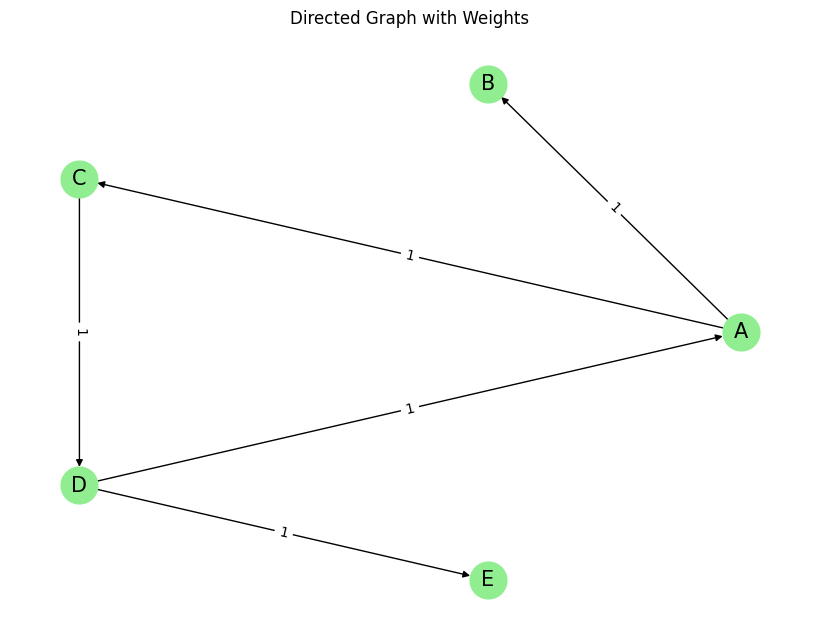

In [72]:
# Create a directed graph
G3 = nx.DiGraph()

# Add nodes
nodes = ["A", "B", "C", "D"]
G3.add_nodes_from(nodes)

# Add directed edges with weights
edges = [("D", "E", 1), ("A", "C", 1), ("C", "D", 1), ("D", "A", 1), ("A", "B", 1)]
G3.add_weighted_edges_from(edges)
G3 = cld_nx.set_node_attributes(G3, 'cld', '3')
G3 = cld_nx.set_node_attributes(G3, 'cld', '3')

# Draw the graph
pos = nx.circular_layout(G3)  # positions for all nodes

plt.figure(figsize=(8, 6))
nx.draw(G3, pos, with_labels=True, node_size=700, node_color='lightgreen', font_size=15, font_color='black', arrows=True)
labels = nx.get_edge_attributes(G3, 'weight')
nx.draw_networkx_edge_labels(G3, pos, edge_labels=labels)

plt.title("Directed Graph with Weights")
plt.show()

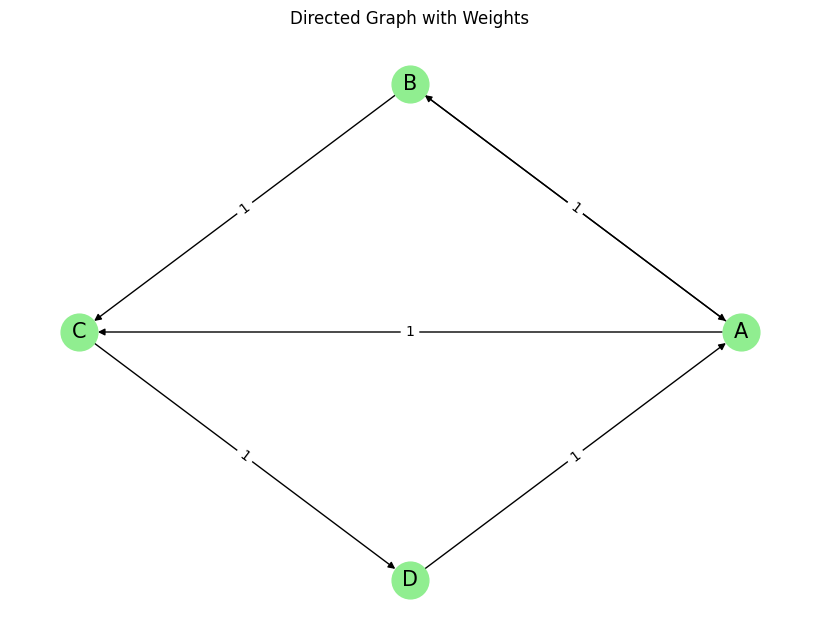

In [65]:
G = nx.compose(G1, G2)

pos = nx.circular_layout(G3)  # positions for all nodes

plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=True, node_size=700, node_color='lightgreen', font_size=15, font_color='black', arrows=True)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.title("Directed Graph with Weights")
plt.show()

In [37]:
A3 = nx.adjacency_matrix(G3)
print(A3.todense())

[[0 1 1 0]
 [1 0 1 0]
 [0 0 0 1]
 [1 0 0 0]]


In [76]:
def to_adjlist(G):
    Al = nx.generate_adjlist(G)
    txt = ""
    for line in Al:
        txt += line + "\n"
    return txt


In [25]:
def adjlist_to_dict(adjlist_str):
    adj_dict = {}
    lines = adjlist_str.strip().split('\n')
    
    for line in lines:
        parts = line.split()
        node = parts[0]
        neighbors = parts[1:]
        if node not in adj_dict:
            adj_dict[node] = {}
        for neighbor in neighbors:
            if neighbor not in adj_dict[node]:
                adj_dict[node][neighbor] = 1
            else:
                adj_dict[node][neighbor] += 1

    return adj_dict

In [26]:
adj_dict = adjlist_to_dict(txt)
adj_dict

{'A': {'B': 1, 'C': 1}, 'B': {'C': 1, 'A': 1}, 'C': {'D': 1}, 'D': {'A': 1}}

In [66]:

def combine_adjacency_dicts(adj_dicts):
    combined_dict = {}
    
    # Initialize combined_dict with all nodes
    for adj in adj_dicts:
        for node in adj:
            if node not in combined_dict:
                combined_dict[node] = {}

            for neighbor in adj[node]:
                if neighbor not in combined_dict[node]:
                    combined_dict[node][neighbor] = 0
                combined_dict[node][neighbor] += adj[node][neighbor]
    
    return combined_dict

def dict_to_adjacency_matrix(adj_dict):
    nodes = list(adj_dict.keys())
    n = len(nodes)
    node_index = {node: i for i, node in enumerate(nodes)}
    adj_matrix = np.zeros((n, n), dtype=int)
    
    for node in adj_dict:
        for neighbor in adj_dict[node]:
            adj_matrix[node_index[node]][node_index[neighbor]] = adj_dict[node][neighbor]
    
    return adj_matrix, nodes

def adjacency_matrix_to_dict(adj_matrix, node_names):
    adj_dict = {node: {} for node in node_names}
    for i, node in enumerate(node_names):
        for j, neighbor in enumerate(node_names):
            if adj_matrix[i][j] > 0:
                adj_dict[node][neighbor] = adj_matrix[i][j]
    return adj_dict




In [39]:
# Example usage
# Define three adjacency dictionaries
# adj_dict1 = {'A': {'B': 1}, 'B': {'C': 1}, 'C': {'A': 1}}
# adj_dict2 = {'A': {'B': 1, 'C': 1}, 'C': {'A': 1}}
# adj_dict3 = {'A': {'D': 1}, 'B': {'D': 1}, 'D': {'B': 1}}

Al1 = to_adjlist(G1)
Al2 = to_adjlist(G2)
Al3 = to_adjlist(G3)

adj_dict1 = adjlist_to_dict(Al1)
adj_dict2 = adjlist_to_dict(Al2)
adj_dict3 = adjlist_to_dict(Al3)


# Combine the adjacency dictionaries
combined_dict = combine_adjacency_dicts([adj_dict1, adj_dict2, adj_dict3])

# Convert combined dictionary to adjacency matrix
combined_matrix, nodes = dict_to_adjacency_matrix(combined_dict)

# Print the result
print("Combined Adjacency Matrix:")
print(combined_matrix)
print("\nNodes:")
print(nodes)

Combined Adjacency Matrix:
[[0 3 2 0]
 [2 0 3 0]
 [0 0 0 3]
 [3 0 0 0]]

Nodes:
['A', 'B', 'C', 'D']


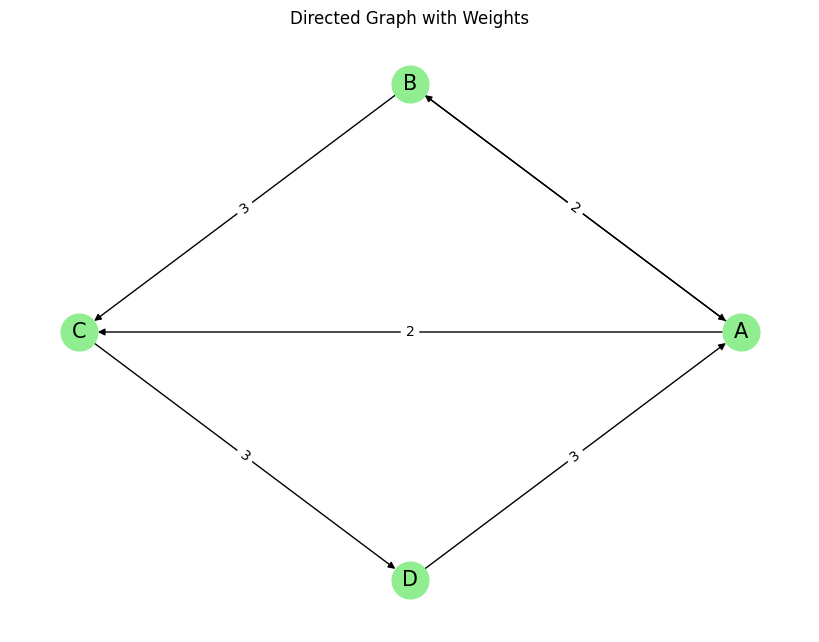

In [47]:
D = nx.from_numpy_array(combined_matrix, create_using=nx.DiGraph)

# add node labels to D 
D = nx.relabel_nodes(D, lambda x: nodes[x])

plt.figure(figsize=(8, 6))

pos = nx.circular_layout(D)  # positions for all nodes

nx.draw(D, pos, with_labels = True, node_size=700, node_color='lightgreen', font_size=15, font_color='black', arrows=True)
labels = nx.get_edge_attributes(D, 'weight')
nx.draw_networkx_edge_labels(D, pos, edge_labels=labels)

plt.title("Directed Graph with Weights")
plt.show()

In [52]:

gv.d3(D, 
        graph_height=200,
        edge_curvature=-0.5,
        # many_body_force_strength=-200, 
        
        # node_size_data_source="degree",
        # use_node_size_normalization=True,
        # node_size_normalization_min=15,
        # node_size_normalization_max=35,
        # show_node_label=True,


    )

In [53]:
cld_nx.cld_nx_properties(D)
cld_nx.cld_nx_node_properties(D)
cld_nx.cld_nx_edge_properties(D)

Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 4
Number of edges: 6
Attributes: {}
Node data:
-------------

Type: <class 'str'> <class 'dict'>
Var Name: A
Attributes: {}
Degree: 4
Type: <class 'str'> <class 'dict'>
Var Name: B
Attributes: {}
Degree: 3
Type: <class 'str'> <class 'dict'>
Var Name: C
Attributes: {}
Degree: 3
Type: <class 'str'> <class 'dict'>
Var Name: D
Attributes: {}
Degree: 2
Edge data:
-------------
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: A
Target: B
Attributes: {'weight': 3}
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: A
Target: C
Attributes: {'weight': 2}
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: B
Target: A
Attributes: {'weight': 2}
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: B
Target: C
Attributes: {'weight': 3}
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: C
Target: D
Attributes: {'weight': 3}
Type: <class 'str'> <class 'str'> <class 'd

In [58]:
import networkx as nx

def combine_graphs_with_node_attributes(graphs):
    combined_graph = nx.DiGraph()

    for g in graphs:
        for node, attrs in g.nodes(data=True):
            if node not in combined_graph:
                combined_graph.add_node(node, **{k: [v] for k, v in attrs.items()})
            else:
                for attr, value in attrs.items():
                    if attr in combined_graph.nodes[node]:
                        combined_graph.nodes[node][attr].append(value)
                    else:
                        combined_graph.nodes[node][attr] = [value]
        
        for u, v, attrs in g.edges(data=True):
            if combined_graph.has_edge(u, v):
                for attr, value in attrs.items():
                    if attr in combined_graph[u][v]:
                        combined_graph[u][v][attr].append(value)
                    else:
                        combined_graph[u][v][attr] = [value]
            else:
                combined_graph.add_edge(u, v, **{k: [v] for k, v in attrs.items()})

    return combined_graph

# Example usage
if __name__ == "__main__":
    # Create first graph G1
    # G1 = nx.DiGraph()
    # G1.add_node('A', cld=1)
    # G1.add_node('B', cld=1)
    # G1.add_edge('A', 'B', weight=2)

    # # Create second graph G2
    # G2 = nx.DiGraph()
    # G2.add_node('A', cld=2)
    # G2.add_node('C', cld=2)
    # G2.add_edge('A', 'C', weight=3)

    # Combine the graphs
    combined_graph = combine_graphs_with_node_attributes([G1, G2])

    # Print nodes and their attributes
    print("Node attributes in the combined graph:")
    for node, attrs in combined_graph.nodes(data=True):
        print(f"{node}: {attrs}")
    
    # Print edges and their attributes
    print("\nEdge attributes in the combined graph:")
    for  attrs in combined_graph.edges(data=True):
        print(f" {attrs}")


Node attributes in the combined graph:
A: {'cld': [1, 2]}
B: {'cld': [1]}
C: {'cld': [2]}

Edge attributes in the combined graph:
 ('A', 'B', {'weight': [2]})
 ('A', 'C', {'weight': [3]})


In [75]:
# Combine the graphs
combined_graph = combine_graphs_with_node_attributes([G1, G2, G3])

# Print nodes and their attributes
print("Node attributes in the combined graph:")
for node, attrs in combined_graph.nodes(data=True):
    print(f"{node}: {attrs}")

# Print edges and their attributes
print("\nEdge attributes in the combined graph:")
for  attrs in combined_graph.edges(data=True):
    print(f" {attrs}")

Node attributes in the combined graph:
A: {'cld': ['1', '2', '3'], 'level': ['org', 'org', 'org'], 'degree': [3, 3, 3]}
B: {'cld': ['1', '2', '3'], 'level': ['org', 'org', 'org'], 'degree': [2, 3, 1]}
C: {'cld': ['1', '2', '3'], 'level': ['org', 'org', 'org'], 'degree': [3, 2, 2]}
D: {'cld': ['1', '2', '3'], 'level': ['org', 'org', 'org'], 'degree': [2, 2, 3]}
E: {'cld': ['3'], 'level': ['org'], 'degree': [1]}

Edge attributes in the combined graph:
 ('A', 'B', {'weight': [1, 1, 1]})
 ('A', 'C', {'weight': [1, 1]})
 ('B', 'C', {'weight': [1, 1]})
 ('B', 'A', {'weight': [1]})
 ('C', 'D', {'weight': [1, 1, 1]})
 ('D', 'A', {'weight': [1, 1, 1]})
 ('D', 'E', {'weight': [1]})
